# Synthetic difference-in-differences: California's tobacco tax

In 1988 California passed Proposition 99, which raised the cigarette tax by 25 cents a pack from
January 1989. Did it reduce smoking? Only one state was treated, so the methods for many treated units
(DML, staggered DiD) do not apply. Two classic tools do:

- **Difference-in-differences** compares California's change with the average change of the other
  states. It assumes parallel trends, but California's sales were already falling faster than the
  average before 1989.
- **Synthetic control** (Abadie, Diamond and Hainmueller, 2010) builds a weighted average of other
  states that tracks California before 1989.

**Synthetic DiD** (Arkhangelsky, Athey, Hirshberg, Imbens and Wager, 2021) combines them. Unit weights
make the controls' path parallel to California's before treatment, up to a constant shift. Time
weights pick the pre-treatment years that best predict the controls' post-treatment level. The
estimate is then a weighted DiD. `dml_rs.SyntheticDID` is a port of the authors' R package
`synthdid` and reproduces it to `1e-9`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dml_rs

warnings.filterwarnings(
    "ignore", message="Bad certificate"
)  # Windows certificate store, while downloading
pd.set_option("display.precision", 3)

df = dml_rs.datasets.fetch_california_prop99()
df.head()

,State,Year,PacksPerCapita,treated
0,Alabama,1970,89.8,0
1,Arkansas,1970,100.3,0
2,Colorado,1970,124.8,0
3,Connecticut,1970,120.0,0
4,Delaware,1970,155.0,0


The data are the `california_prop99` panel of `synthdid`: cigarette sales in packs per capita for 39
states from 1970 to 2000. The other 38 states had no large tax increase or tobacco programme in
this period (the donor pool of Abadie et al. excludes states that did). `treated` is 1 for
California from 1989 on.

In [2]:
df.pivot_table(
    index="Year",
    columns=df["State"]
    .eq("California")
    .map({True: "California", False: "other states"}),
    values="PacksPerCapita",
).loc[[1970, 1980, 1988, 1995, 2000]]

State,California,other states
Year,,
1970,123.0,120.084
1980,120.2,138.089
1988,90.1,113.824
1995,56.4,103.158
2000,41.6,92.134


## Three estimators

`fit_panel` takes the long panel and arranges it as `synthdid::panel.matrices` does. The same class
gives synthetic DiD (`estimator="sdid"`, the default), synthetic control (`"sc"`) and plain DiD
(`"did"`). The standard errors use the placebo method. Each control state in turn is treated as if it
were treated, which is the only option with a single treated unit.

In [3]:
fits = {
    est: dml_rs.SyntheticDID(estimator=est).fit_panel(
        df, "State", "Year", "PacksPerCapita", "treated"
    )
    for est in ["sdid", "sc", "did"]
}
pd.concat([f.summary for f in fits.values()])

,coef,std err,t,P>|t|,2.5 %,97.5 %
synthetic DiD,-15.604,9.727,-1.604,0.109,-34.668,3.46
synthetic control,-19.620,10.949,-1.792,0.073,-41.079,1.84
DiD,-27.349,17.923,-1.526,0.127,-62.478,7.78


These are the point estimates of Table 1 in Arkhangelsky et al. (2021): −15.6 packs per capita for
synthetic DiD, −19.6 for synthetic control and −27.3 for DiD. The placebo standard errors depend on
the random placebo draws, so they differ slightly from the paper's. With `random_state` set, they
equal R's after `set.seed`.

The plots show why the estimates differ. DiD compares California with the plain average of all
states, which declined more slowly before 1989. Synthetic control matches California's level.
Synthetic DiD matches its trend, up to a constant shift, and weights the years just before 1989
(grey bars).

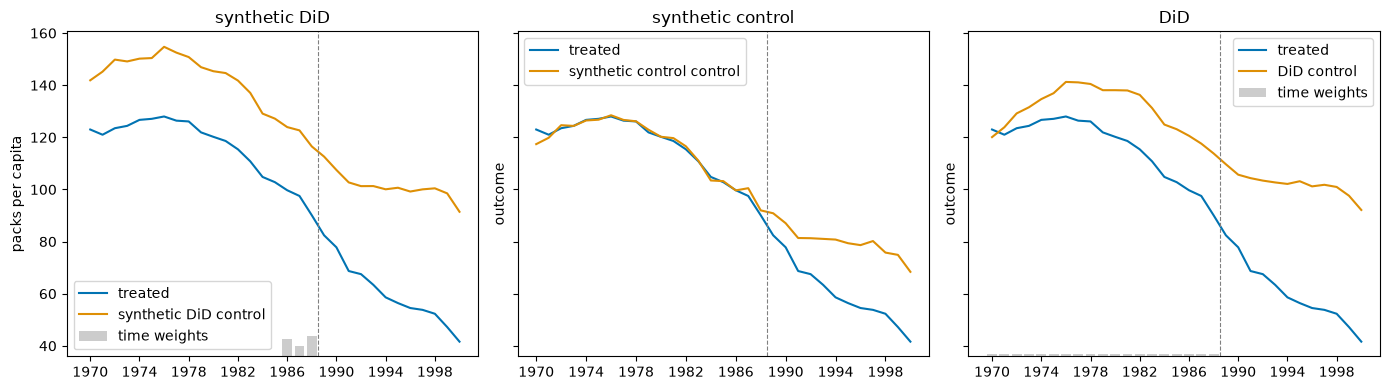

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (est, f) in zip(axes, fits.items()):
    f.plot(ax=ax)
    ax.set_title(f.summary.index[0])
axes[0].set_ylabel("packs per capita")
fig.tight_layout()

## Unit and time weights

Synthetic DiD spreads its unit weights over many states. Synthetic control concentrates them on a
few. The time weights fall on 1986–1988.

In [5]:
weights = pd.DataFrame(
    {
        "synthetic DiD": fits["sdid"].unit_weights_,
        "synthetic control": fits["sc"].unit_weights_,
    }
)
print("states with positive weight:", (weights > 0).sum().to_dict())
weights.sort_values("synthetic DiD", ascending=False).head(8)

states with positive weight: {'synthetic DiD': 28, 'synthetic control': 7}


,synthetic DiD,synthetic control
Nevada,0.124,0.204
New Hampshire,0.105,0.045
Connecticut,0.078,0.104
Delaware,0.070,0.004
Colorado,0.058,0.013
Illinois,0.053,0.000
Nebraska,0.048,0.000
Montana,0.045,0.232


In [6]:
fits["sdid"].time_weights_[fits["sdid"].time_weights_ > 0]

1986    0.366
1987    0.206
1988    0.427
dtype: float64

## Effect over time

`effect_curve_` is the estimated effect in each post-treatment year: the gap between California and
its synthetic control, net of the weighted pre-treatment gap. The effect grows steadily from about −5
packs in 1989 to about −25 by the late 1990s.

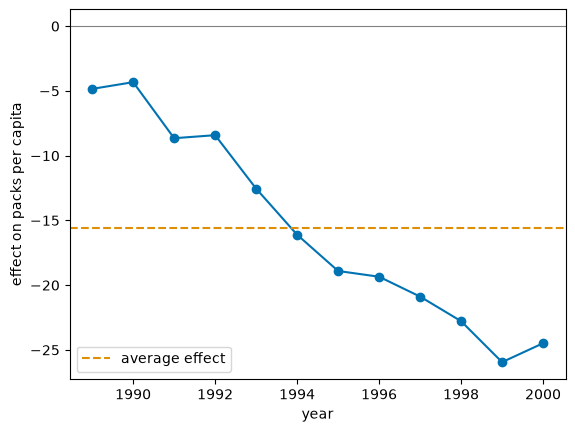

In [7]:
curve = fits["sdid"].effect_curve_
ax = curve.plot(marker="o", color="#0173B2")
ax.axhline(
    fits["sdid"].coef_[0],
    color="#DE8F05",
    ls="--",
    label="average effect",
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("year")
ax.set_ylabel("effect on packs per capita")
ax.legend();

## A placebo check in time

If the method works, it should find no effect where there was none. Keep only the years before 1989
and pretend the tax started in 1980. `fit` takes the units × periods matrix directly, with the
control units in the first rows and the pre-treatment periods in the first columns.

In [8]:
wide = df.pivot(index="State", columns="Year", values="PacksPerCapita")
order = [s for s in wide.index if s != "California"] + ["California"]
pre = wide.loc[order, wide.columns < 1989]

placebo = dml_rs.SyntheticDID().fit(
    pre.to_numpy(),
    n_control=38,
    n_pre=list(pre.columns).index(1980),
    units=order,
    periods=list(pre.columns),
)
placebo.summary

,coef,std err,t,P>|t|,2.5 %,97.5 %
synthetic DiD,-2.925,7.182,-0.407,0.684,-17.001,11.151


The fake effect is small and far from significant. That supports the identifying assumption: the
weighted controls would have tracked California without the tax.

## Inference with one treated unit

The jackknife and bootstrap standard errors need at least two treated units. With one, the placebo
method is the only choice. It assumes the treated unit's noise behaves like a control unit's. More
replications reduce simulation noise in the standard error:

In [9]:
sdid = fits["sdid"]
pd.Series(
    {r: sdid.se("placebo", replications=r) for r in [100, 200, 1000]},
    name="placebo se",
)

100     10.005
200      9.727
1000     9.603
Name: placebo se, dtype: float64

With about 10 packs per capita of standard error, the effect is not significant at 5% (as in the
paper). One treated state carries limited information however the comparison is built.

## Summary

- `SyntheticDID` estimates effects for a few treated units with a simultaneous start. `fit_panel`
  takes a long panel and `fit` a units × periods matrix. Time-varying covariates go in
  `covariates=` / `X=`.
- `estimator="sc"` and `"did"` give synthetic control and DiD from the same class, which makes them
  easy to compare.
- `unit_weights_`, `time_weights_`, `effect_curve_` and `plot` show what the estimate is built from.
  A placebo check in time tests the identifying assumption.